In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import re
import zipfile
from io import BytesIO
from tqdm import tqdm  # For progress bars

In [2]:
!ls "/kaggle/input/dataset-patching/dataset/"

test_data  train_data  train_labels.csv  train_masks_cleaned.npy


In [3]:
# --- Configuration ---

# Folders
INPUT_DIR = '/kaggle/input/dataset-patching/dataset/'
OUTPUT_DIR = '/kaggle/working/'
TRAIN_IMG_DIR = os.path.join(INPUT_DIR, 'train_data')
TEST_IMG_DIR = os.path.join(INPUT_DIR, 'test_data')

# Parameters
PATCH_SIZE = 224
STRIDE = 224  # Step size. If equal to PATCH_SIZE, no overlap.
TISSUE_THRESHOLD = 0.003  # Keep patch if at least a certain % of it, it's tissue (according to mask)

In [4]:
def create_patches(image, mask, patch_size, stride, threshold):
    """
    Slices an image into patches and filters them based on the mask.
    Returns: List of image patches, List of mask patches
    """
    img_h, img_w = image.shape[:2]
    patches_img = []
    patches_mask = []
    
    # Iterate over the image with the sliding window
    for y in range(0, img_h - patch_size + 1, stride):
        for x in range(0, img_w - patch_size + 1, stride):
            
            # Crop the mask patch first to check if it's useful
            mask_patch = mask[y:y+patch_size, x:x+patch_size]
            
            # Calculate tissue percentage (assuming mask is 0 or 255/1)
            # If your mask is 0-255, divide by 255 first or change logic
            tissue_ratio = np.mean(mask_patch > 0) 
            
            if tissue_ratio >= threshold:
                # If useful, crop the image patch
                img_patch = image[y:y+patch_size, x:x+patch_size]
                
                patches_img.append(img_patch)
                patches_mask.append(mask_patch)
                
    return patches_img, patches_mask

In [5]:
# --- Helper: Find Matching Mask ---
def find_mask_for_image(img_name, all_files):
    """
    Tries to find a mask file that matches the image ID.
    Example: img_001.png -> looks for mask_001.png or img_001_mask.png
    """
    # Extract the numeric ID from the filename (e.g., '001' from 'img_001.png')
    img_id_match = re.search(r'(\d+)', img_name)
    if not img_id_match:
        return None
    
    img_id = img_id_match.group(1)
    
    # Search for a file that contains this ID and the word "mask"
    for f in all_files:
        if img_id in f and 'mask' in f.lower() and f.endswith('.png'):
            return f
    return None

In [6]:
# --- Load Labels ---
train_df = pd.read_csv(os.path.join(INPUT_DIR, 'train_labels.csv'))
# Map text labels to integers
label_mapping = {
    'Luminal A': 0, 'Luminal B': 1, 'HER2(+)': 2, 'Triple negative': 3
}
train_df['target'] = train_df['label'].map(label_mapping)

In [7]:
# --- 1. Process Training Data ---
print(f"Scanning {TRAIN_IMG_DIR}...")
# Get list of all files in train folder once to speed up search
all_train_files = os.listdir(TRAIN_IMG_DIR)
# Filter out only the actual tissue images (exclude masks for now)
train_images_list = [f for f in all_train_files if f.endswith('.png') and 'mask' not in f.lower()]
print(f"Found {len(train_images_list)} train images. Starting patching...")

# Processing Lists 
X_train_patches = []
y_train_patches = []
train_masks_patches = []
train_groups = [] # To track which original image the patch came from (for splitting)

# Processing
for index, row in tqdm(train_df.iterrows(), total=len(train_df)):
    filename = row['sample_index']
    label = row['target']
    
    # 1. Read Image
    img_path = os.path.join(TRAIN_IMG_DIR, filename)
    if not os.path.exists(img_path):
        print(f"Warning: {filename} not found.") 
        continue
        
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # 2. Find Corresponding Mask in the SAME folder
    mask_filename = find_mask_for_image(filename, all_train_files)
    
    if mask_filename:
        mask_path = os.path.join(TRAIN_IMG_DIR, mask_filename)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    else:
        # Fallback: If no mask file exists, use full image (or skip)
        # Assuming if mask is missing, we keep the whole image
        print(f"Note: No mask found for {filename}, using full image.")
        mask = np.ones((image.shape[0], image.shape[1]), dtype=np.uint8) * 255
        
    # 3. Generate Patches 
    p_imgs, p_masks = create_patches(image, mask, PATCH_SIZE, STRIDE, TISSUE_THRESHOLD)
    
    # 4. Store
    for p_img, p_mask in zip(p_imgs, p_masks):
        X_train_patches.append(p_img)
        train_masks_patches.append(p_mask)
        y_train_patches.append(label)
        train_groups.append(filename)

# Convert to Numpy Arrays
X_train = np.array(X_train_patches)
y_train = np.array(y_train_patches)
train_masks = np.array(train_masks_patches)
train_groups = np.array(train_groups)

# Add channel dim
if len(train_masks.shape) == 3:
    train_masks = np.expand_dims(train_masks, axis=-1)

print(f"\nGenerated {len(X_train)} train patches from {len(train_images_list)} images.")
print(f"X_train shape: {X_train.shape}")

# Save to output
np.save(os.path.join(OUTPUT_DIR, 'train_patches_images.npy'), X_train)
np.save(os.path.join(OUTPUT_DIR, 'train_patches_masks.npy'), train_masks)
np.save(os.path.join(OUTPUT_DIR, 'train_patches_labels.npy'), y_train)
np.save(os.path.join(OUTPUT_DIR, 'train_patches_groups.npy'), train_groups)

print("\n✅ Patching Train Set completed. Files saved.")

Scanning /kaggle/input/dataset-patching/dataset/train_data...
Found 629 train images. Starting patching...


100%|██████████| 629/629 [00:32<00:00, 19.29it/s]



Generated 3946 train patches from 629 images.
X_train shape: (3946, 224, 224, 3)

✅ Patching Train Set completed. Files saved.


In [8]:
# --- 2. Process Test Data ---
print(f"Scanning {TEST_IMG_DIR}...")
all_test_files = os.listdir(TEST_IMG_DIR)

# Filter out only the actual tissue images (exclude masks for now)
test_images_list = [f for f in all_test_files if f.endswith('.png') and 'mask' not in f.lower()]

print(f"Found {len(test_images_list)} test images. Starting patching...")

# Processing Lists
X_test_patches = []
test_masks_patches = []
test_groups = [] # To track which image the patch came from

# Processing
for filename in tqdm(test_images_list):
    img_path = os.path.join(TEST_IMG_DIR, filename)
    
    # 1. Read Image
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # 2. Find and Read Corresponding Mask
    mask_filename = find_mask_for_image(filename, all_test_files)
    
    if mask_filename:
        mask_path = os.path.join(TEST_IMG_DIR, mask_filename)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    else:
        # Fallback if no mask found: use whole image
        print(f"Warning: No mask found for {filename}. Keeping all patches.")
        mask = np.ones((image.shape[0], image.shape[1]), dtype=np.uint8) * 255

    # 3. Create Patches using the Mask
    p_imgs, p_masks = create_patches(image, mask, PATCH_SIZE, STRIDE, TISSUE_THRESHOLD)
    
    # 4. Store
    for p_img, p_mask in zip(p_imgs, p_masks):
        X_test_patches.append(p_img)
        test_masks_patches.append(p_mask)
        test_groups.append(filename) 

# Convert to Numpy Arrays
X_test = np.array(X_test_patches)
test_masks = np.array(test_masks_patches)
test_groups = np.array(test_groups)

# Add channel dimension to masks (N, 224, 224, 1)
if len(test_masks.shape) == 3:
    test_masks = np.expand_dims(test_masks, axis=-1)

print(f"\nGenerated {len(X_test)} test patches from {len(test_images_list)} images.")
print(f"X_test shape: {X_test.shape}")

# Save to output
np.save(os.path.join(OUTPUT_DIR, 'test_patches_images.npy'), X_test)
np.save(os.path.join(OUTPUT_DIR, 'test_patches_masks.npy'), test_masks)
np.save(os.path.join(OUTPUT_DIR, 'test_patches_groups.npy'), test_groups)

print("\n✅ Patching Test Set complete. Files saved.")

Scanning /kaggle/input/dataset-patching/dataset/test_data...
Found 477 test images. Starting patching...


100%|██████████| 477/477 [00:25<00:00, 18.72it/s]



Generated 2773 test patches from 477 images.
X_test shape: (2773, 224, 224, 3)

✅ Patching Test Set complete. Files saved.



--- RECONSTRUCTING FROM SAVED TRAIN ARRAYS ---
Selected Image ID: img_0460.png
-> Found 7 patches saved for this image.


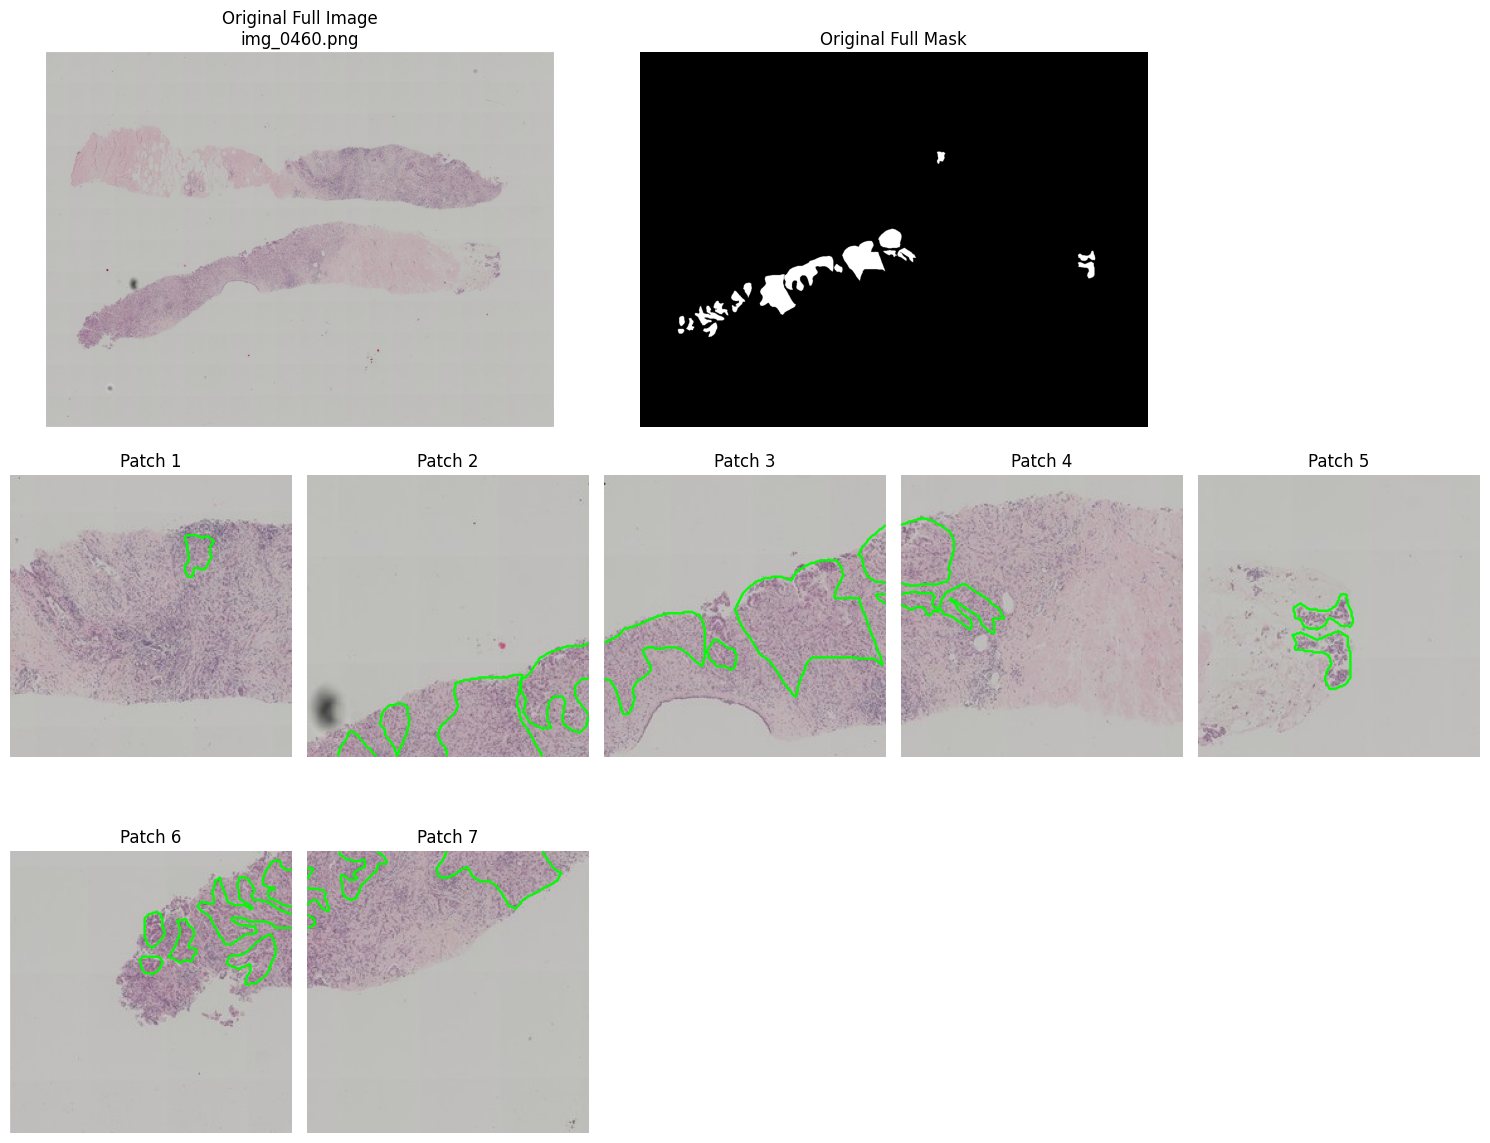


--- RECONSTRUCTING FROM SAVED TEST ARRAYS ---
Selected Image ID: img_0290.png
-> Found 6 patches saved for this image.


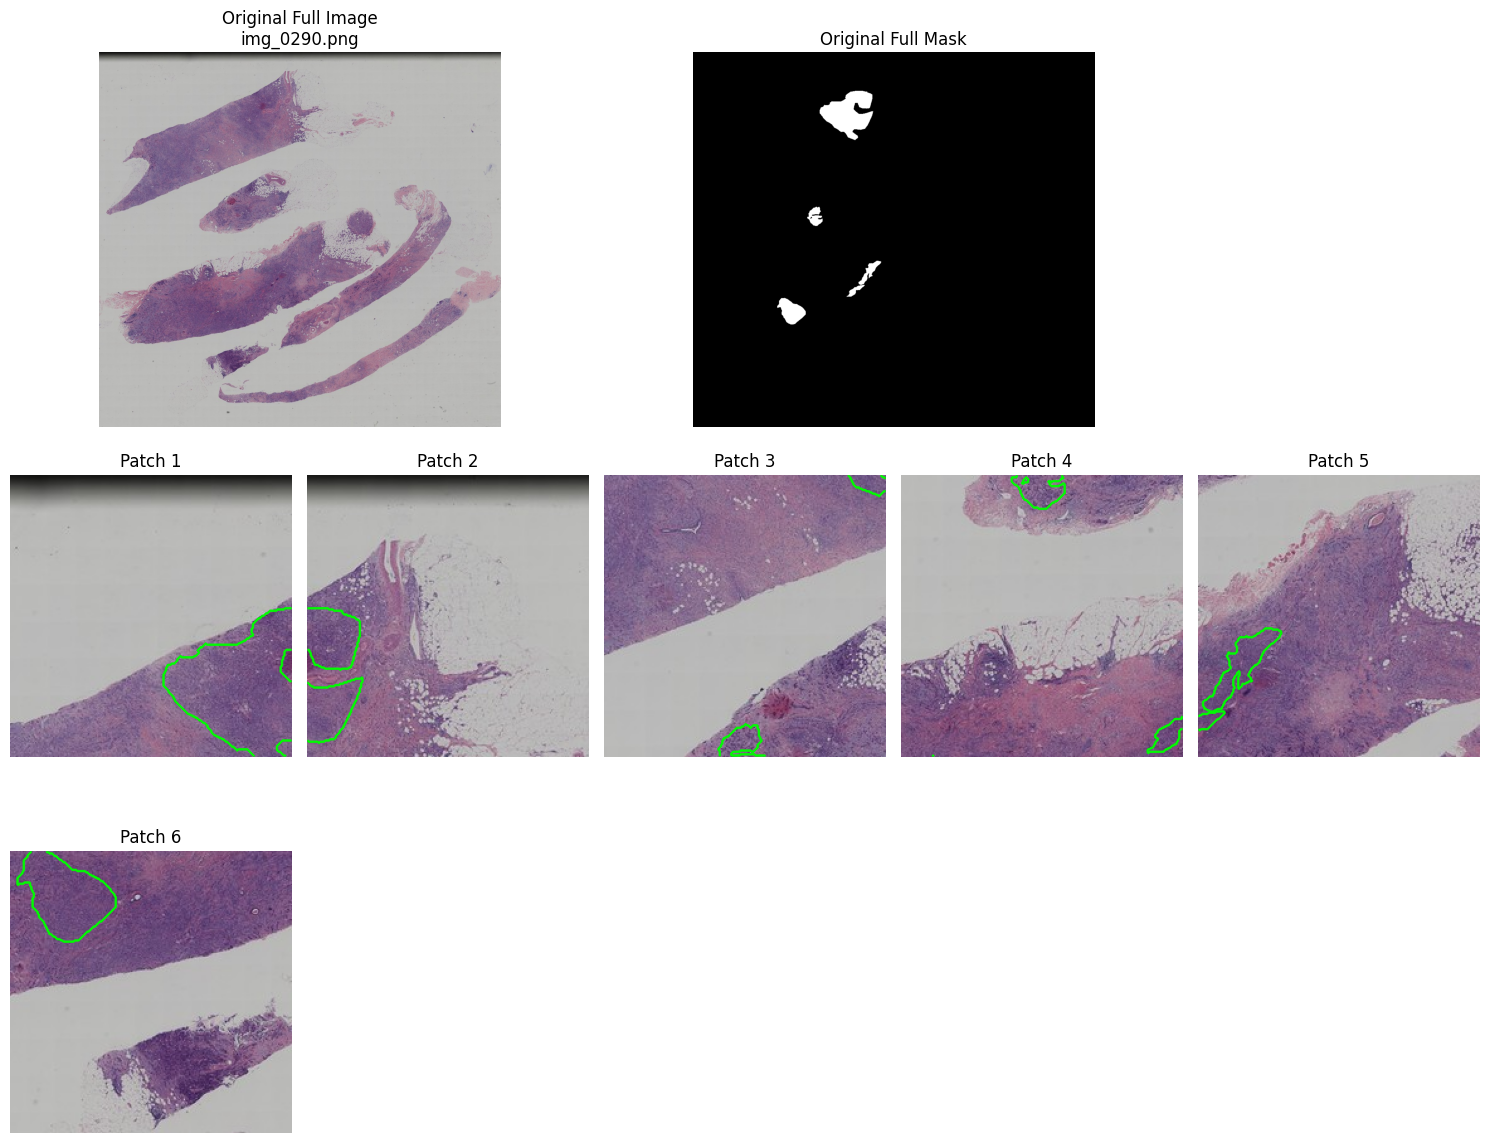

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import random
import re


# --- Helper: Find Mask File ---
def find_mask_file(img_name, folder):
    """Finds the mask file corresponding to the image name."""
    match = re.search(r'(\d+)', img_name)
    if not match: return None
    img_id = match.group(1)
    
    for f in os.listdir(folder):
        if img_id in f and 'mask' in f.lower() and f.endswith('.png'):
            return os.path.join(folder, f)
    return None



def visualize_from_saved_arrays(subset='train'):
    print(f"\n--- RECONSTRUCTING FROM SAVED {subset.upper()} ARRAYS ---")
    
    # 1. Load the Groups (to know which patch belongs to which image)
    groups_path = os.path.join(OUTPUT_DIR, f'{subset}_patches_groups.npy')
    images_path = os.path.join(OUTPUT_DIR, f'{subset}_patches_images.npy')
    masks_path = os.path.join(OUTPUT_DIR, f'{subset}_patches_masks.npy')
    
    if not os.path.exists(groups_path):
        print(f"❌ Files not found for {subset}. Did you run the processing step?")
        return

    # Load groups fully, but load images/masks in 'mmap' mode to save RAM
    groups = np.load(groups_path)
    all_patches_img = np.load(images_path, mmap_mode='r')
    all_patches_mask = np.load(masks_path, mmap_mode='r')
    
    # 2. Pick a Random Unique Image ID from the processed data
    unique_ids = np.unique(groups)
    if len(unique_ids) == 0:
        print("⚠️ No data found in the arrays.")
        return
        
    selected_id = random.choice(unique_ids)
    print(f"Selected Image ID: {selected_id}")
    
    # 3. Find all patches belonging to this Image ID
    # This gives us the indices in the big array
    patch_indices = np.where(groups == selected_id)[0]
    print(f"-> Found {len(patch_indices)} patches saved for this image.")
    
    # 4. Load ALL create patches of the image 
    sample_indices = patch_indices 
    
    sample_patches = all_patches_img[sample_indices]
    sample_masks = all_patches_mask[sample_indices]

    # 5. Load Original Full Image/Mask from Disk (For Comparison Only)
    folder = TRAIN_IMG_DIR if subset == 'train' else TEST_IMG_DIR
    
    # Original Image
    orig_img_path = os.path.join(folder, selected_id)
    if os.path.exists(orig_img_path):
        orig_img = cv2.imread(orig_img_path)
        orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    else:
        orig_img = np.zeros((100,100,3), dtype=np.uint8) # Dummy if missing
        
    # Original Mask
    orig_mask_path = find_mask_file(selected_id, folder)
    if orig_mask_path:
        orig_mask = cv2.imread(orig_mask_path, cv2.IMREAD_GRAYSCALE)
    else:
        orig_mask = np.zeros(orig_img.shape[:2], dtype=np.uint8)

    
    # --- PLOTTING ---
    # Calculate grid dimensions based on number of patches
    num_patches = len(sample_patches)
    cols = 5
    # Calculate required rows: 1 row for original images + rows for patches
    patch_rows = (num_patches + cols - 1) // cols 
    total_rows = 1 + patch_rows if num_patches > 0 else 2
    
    # Adjust figure height dynamically (approx 4 units per row)
    fig = plt.figure(figsize=(15, 4 * total_rows))
    
    # Top Row: Originals (spans 2 columns each)
    # Note: We update the grid size to (total_rows, cols)
    ax1 = plt.subplot2grid((total_rows, cols), (0, 0), colspan=2)
    ax1.imshow(orig_img)
    ax1.set_title(f"Original Full Image\n{selected_id}")
    ax1.axis('off')
    
    ax2 = plt.subplot2grid((total_rows, cols), (0, 2), colspan=2)
    ax2.imshow(orig_mask, cmap='gray')
    ax2.set_title("Original Full Mask")
    ax2.axis('off')
    
    # Bottom Rows: The Patches retrieved from .npy
    if num_patches > 0:
        for i in range(num_patches):
            # Calculate grid position (starting from row 1)
            r = 1 + (i // cols)
            c = i % cols
            
            ax = plt.subplot2grid((total_rows, cols), (r, c))
            
            # Show Image Patch
            ax.imshow(sample_patches[i])
            
            # Overlay mask contour
            m = sample_masks[i].squeeze()
            ax.contour(m, colors='lime', linewidths=1, alpha=0.5)
            
            ax.set_title(f"Patch {i+1}")
            ax.axis('off')
    else:
        print("No patches to display.")

    plt.tight_layout()
    plt.show()


# --- Run ---
visualize_from_saved_arrays('train')
visualize_from_saved_arrays('test')